In [1]:
import os
import shutil
import pandas as pd
from glob import glob
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from skimage import io
import math

# 4 Application pipeline

This notebuc descrebes the final state of the proposed data processing pipeline in a scope of an environmental research.

In [2]:
from common.configuration import ModelPath, DatasetPath, species_invasive, species_native
from pipeline.full_predict import ImageProcessor
from common.configuration import DatasetPath, ModelPath, species_native, species_label_map_all, species_classes_map_all

In [3]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

In [4]:
image_processor = ImageProcessor(ModelPath.instance_segmentation, ModelPath.osc_classification, prediction_to_class_name)

### Real-world samples dataset

 Plot some samples to test dataset

In [5]:
segmentation_input_dir = DatasetPath.real_historical_samples#os.path.join(DatasetPath.real_historical_samples, "april 10")
# segmentation_input_dir = r"Dataset\pollen_dataset_2025_02_05\samples\Betula"
images = glob(os.path.join(segmentation_input_dir, "**","*.jpg"))

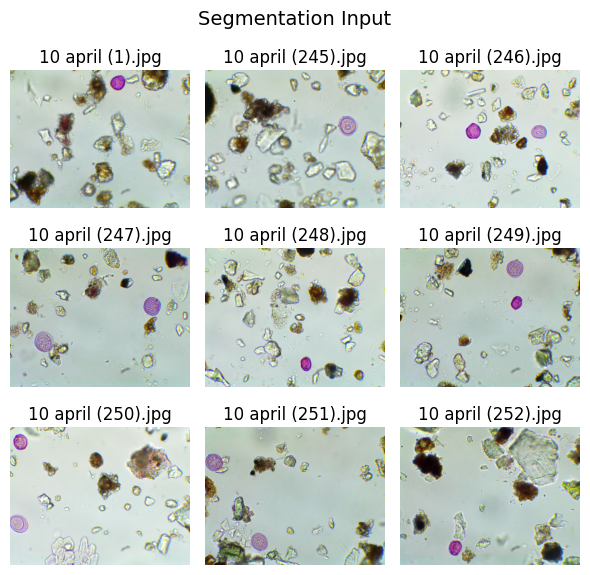

In [6]:
# Plot some samples
samples = images[0:9]
n = math.ceil(len(samples) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n*2, n*2))
for ax, img_path in zip(axs.flatten(), samples):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path))
for ax in axs.flatten()[len(samples):]:
    ax.set_visible(False)
fig.suptitle('Segmentation Input', fontsize=14)
plt.tight_layout()
plt.show()

### Process all images

In [7]:
segmentation_output_dir = "Save/app_pipeline/segmentation_output_sample"

In [8]:
if os.path.exists(segmentation_output_dir):
    shutil.rmtree(segmentation_output_dir)
os.makedirs(segmentation_output_dir, exist_ok=False)

### Compare with manual data

In [9]:
subsets = os.listdir(segmentation_input_dir)
subsets = list(filter(lambda x: os.path.isdir(os.path.join(segmentation_input_dir, x)), subsets))
print(subsets)

['april 10', 'april 12', 'april 16', 'april 18', 'august 1', 'august 15', 'august 16', 'august 25', 'august 27', 'august 28', 'august 29', 'august 30', 'august 4', 'july 1', 'july 14', 'july 7', 'june 10', 'june 17', 'june 25', 'may 1', 'may 21', 'september 1', 'september 2']


In [10]:
prediction_summary_path = "Save/historical_predictions_summary.csv"
embeddings_data_path = "Save/historical_embeddings.csv"

In [11]:
sample_wize_data = []

if os.path.exists(prediction_summary_path):
    full_stats_pd = pd.read_csv(prediction_summary_path, index_col=0)
else:
    full_stats_pd = pd.DataFrame()
for i, subset_dir_name in enumerate(subsets):
    print(20*"=")
    print(f"Process {subset_dir_name}, {i+1}/{len(subsets)}")
    print(20*"=")
    if subset_dir_name in full_stats_pd.index:
        print("Computations already done, skip processing")
        continue
    all_obj_images = glob(os.path.join(segmentation_input_dir,
                                       subset_dir_name, 
                                       "*.jpg"), recursive=False)
    obj_stats = {}
    for image_path in tqdm(all_obj_images):
        pred_labels = image_processor.process_image(image_path=image_path,
                                                    crops_path=segmentation_output_dir,
                                                    augment = 4,
                                                    with_embeddings=True)
        for i, pred_class in enumerate(pred_labels):
            sample_wize_data.append(
                {
                    "subset":subset_dir_name,
                    "image":image_path,
                    "pollen_n": i,
                    "embeddings": pred_class[1]
                }
            )
            if pred_class[0] in obj_stats:
                obj_stats[pred_class[0]] += 1
            else:
                obj_stats[pred_class[0]] = 1
    obj_stats_pd = pd.Series(obj_stats, name=subset_dir_name).to_frame().T
    full_stats_pd = pd.concat([full_stats_pd, obj_stats_pd], axis=0)
    full_stats_pd.to_csv(prediction_summary_path)


embeddings_pd = pd.DataFrame(sample_wize_data)
embeddings_pd.to_csv(embeddings_data_path)

Process april 10, 1/23


  0%|          | 0/279 [00:00<?, ?it/s]

i:\git\Pollen-Analyzer\common\osc_classification.py:94: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4419.)
  scores[range(scores.shape[0]), candidate.T] < threshold, candidate, -1)
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


3 is duplicate of 2
4 is duplicate of 3
Process april 12, 2/23


  0%|          | 0/270 [00:00<?, ?it/s]

...

i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


Process september 2, 23/23


  0%|          | 0/191 [00:00<?, ?it/s]

i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


7 is duplicate of 0
2 is duplicate of 0
